# Thermal phase change – energy demand model

*Thermal separation › Thermal phase change* (manuscript Fig. 1)

**Examples** (Fig. 1). All three use the same model; the examples change nothing in the equations.
| Process | Products |
|---|---|
| Distillation | alcohol, beverages, chemical solvents, essential oils, purified water |
| Evaporation | fruit juice concentrate, milk and whey concentrate, sugar syrup |
| Stripping | oil and gas, ammonia, phenol |

A liquid feed is heated to its boiling temperature $T_v$ and the component with the lower boiling point
(mass fraction $w$) is evaporated. The vapour is condensed and both products (distillate and residue)
are cooled to $T_{out}$ (manuscript section *Thermal phase change*, Fig. 8).

$$\dot Q_{heating}=\dot m\,w\,\big(h_v+c_{p,1}\,(T_v-T_{in})\big)+\dot m\,(1-w)\,c_{p,2}\,(T_v-T_{in})\quad(20)$$
$$\dot Q_{cooling}=\dot m\,w\,\big(h_v+c_{p,1}\,(T_v-T_{out})\big)+\dot m\,(1-w)\,c_{p,2}\,(T_v-T_{out})\quad(21)$$

$c_{p,1}$, $h_v$: evaporated component; $c_{p,2}$: residue. This notebook holds no formulas of its own: it
imports **`model.py`**, the model the app runs.

1. Example calculations
2. Figures and simplified P&ID (saved as `pid.svg`)
3. Validation against the manuscript and consistency checks
4. Comparison with an existing implementation

In [1]:
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from matplotlib.patches import Rectangle, Circle, FancyBboxPatch, Polygon
from IPython.display import display, Markdown

try:
    import process_models
except ImportError:            # not installed: use the copy in this repository
    import sys
    sys.path.insert(0, str(Path.cwd().parents[1]))   # .../process_models (the folder holding the package)

from process_models import PROCESSES, run_process
from process_models.thermal_phase_change.model import MODEL, calculate

KEY = MODEL.key

pd.set_option("display.float_format", lambda x: f"{x:,.3f}")
pd.set_option("display.max_colwidth", 90)
pd.set_option("display.width", 200)
plt.rcParams.update({"figure.dpi": 110, "axes.grid": True, "grid.alpha": 0.3, "font.size": 10})

print(f"{MODEL.name} v{MODEL.version} | processes found by the app: {list(PROCESSES)}")

Thermal phase change v1.0 | processes found by the app: ['autoclaving', 'conductive_drying', 'continuous_bath_heating', 'continuous_heating_of_fluid', 'convective_drying', 'thermal_phase_change']


## 1  Example calculations
The input values are **illustrative, not from the manuscript** (the manuscript gives none for this process).

**1a Distillation:** ethanol from a water mixture. Required inputs plus $w$ and the component; cp and $h_v$ of
ethanol come from the preset.

In [2]:
result, audit = run_process(KEY, mass_flow_kg_h=1000, T_in=20, T_v=92, T_out=25, cp_residue=4.19,
                            w=0.1, component="Ethanol")

display(Markdown("**Inputs** (required / optional, source of each value)"))
display(pd.DataFrame(audit))
for w in result.warnings:
    print("WARNING:", w)
display(Markdown("**Results**"))
display(pd.DataFrame(result.summary()))
display(Markdown("**Stream data** (what the app hands to the pinch analysis)"))
display(pd.DataFrame(result.stream_table()))

**Inputs** (required / optional, source of each value)

,Symbol,Input,Value,Unit,Type,Source,Manuscript / note
0,m_product,Feed mass flow rate,"1,000.000",kg/h,required,user input,"Sect. 'Thermal phase change', input list"
1,T_in,Feed inlet temperature,20.000,degC,required,user input,"Sect. 'Thermal phase change', input list"
2,T_v,Boiling temperature,92.000,degC,required,user input,"Sect. 'Thermal phase change', input list"
3,T_out,Outlet temperature of both products after cooling,25.000,degC,required,user input,"Sect. 'Thermal phase change', input list"
4,"cp,product2",Specific heat capacity of the residue (component not evaporated),4.190,kJ/(kg K),required,user input,"Sect. 'Thermal phase change', input list"
5,w,Mass fraction of the evaporated component,0.100,-,optional,user input,"Sect. 'Thermal phase change', input list | Give w or the evaporated mass flow (manuscr..."
6,m_product*w,Mass flow of the evaporated component,None,kg/h,optional,derived default,"Sect. 'Thermal phase change', input list | Alternative to w: w = evaporated mass flow ..."
7,,Evaporated component (selects default cp and h_v),Ethanol,-,optional,user input,Only used to pick defaults if cp_evaporated or h_v is not given.
8,"cp,product1",Specific heat capacity of the evaporated component (liquid),2.440,kJ/(kg K),optional,"preset (Ethanol), not from manuscript","Sect. 'Thermal phase change', input list | Required in the manuscript; here optional -..."
9,h_v,Latent heat of vaporization of the evaporated component,841.000,kJ/kg,optional,"preset (Ethanol, normal boiling point), not from manuscript","Sect. 'Thermal phase change', input list | Required in the manuscript; here optional -..."


**Results**

,Quantity,Symbol,Value,Unit,Manuscript ref.
0,"Sensible heating, evaporated component",m*w*cp1*(T_v - T_in),4.880,kW,"Eq. (20), 1st term"
1,"Latent heat, evaporation",m*w*h_v,23.361,kW,"Eq. (20), 1st term"
2,"Sensible heating, residue",m*(1-w)*cp2*(T_v - T_in),75.420,kW,"Eq. (20), 2nd term"
3,HEATING DEMAND,Q_heating,103.661,kW,Eq. (20)
4,"Latent heat, condensation",m*w*h_v,23.361,kW,"Eq. (21), 1st term"
5,"Sensible cooling, distillate",m*w*cp1*(T_v - T_out),4.541,kW,"Eq. (21), 1st term"
6,"Sensible cooling, residue",m*(1-w)*cp2*(T_v - T_out),70.183,kW,"Eq. (21), 2nd term"
7,COOLING DEMAND,Q_cooling,98.085,kW,Eq. (21)
8,Evaporated mass flow,m*w,100.000,kg/h,-
9,Heat capacity flow rate (liquid),m*(w*cp1 + (1-w)*cp2),1.115,kW/K,-


**Stream data** (what the app hands to the pinch analysis)

,stream,type,T_supply_degC,T_target_degC,CP_kW_per_K,Q_kW
0,feed preheating,cold,20.000,92.000,1.115,80.300
1,evaporation,cold,92.000,93.000,23.361,23.361
2,condensation,hot,92.000,91.000,23.361,23.361
3,product cooling,hot,92.000,25.000,1.115,74.724


**1b Evaporation:** fruit juice concentrated from 12 to 48 °Brix under vacuum at 70 °C. Here the evaporated
mass flow is given instead of $w$ (5000 kg/h · (1 − 12/48) = 3750 kg/h), and $h_v$ of water at 70 °C instead of
the preset at 100 °C.

In [3]:
evap, evap_audit = run_process(KEY, mass_flow_kg_h=5000, T_in=20, T_v=70, T_out=20, cp_residue=3.0,
                               evaporated_flow_kg_h=3750, component="Water", h_v=2333)
display(pd.DataFrame(evap_audit)[["Input", "Value", "Unit", "Source"]])
display(pd.DataFrame(evap.summary()))

,Input,Value,Unit,Source
0,Feed mass flow rate,"5,000.000",kg/h,user input
1,Feed inlet temperature,20.000,degC,user input
2,Boiling temperature,70.000,degC,user input
3,Outlet temperature of both products after cooling,20.000,degC,user input
4,Specific heat capacity of the residue (component not evaporated),3.000,kJ/(kg K),user input
5,Mass fraction of the evaporated component,0.750,-,evaporated mass flow / feed mass flow
6,Mass flow of the evaporated component,"3,750.000",kg/h,user input
7,Evaporated component (selects default cp and h_v),Water,-,user input
8,Specific heat capacity of the evaporated component (liquid),4.190,kJ/(kg K),"preset (Water), not from manuscript"
9,Latent heat of vaporization of the evaporated component,"2,333.000",kJ/kg,user input


,Quantity,Symbol,Value,Unit,Manuscript ref.
0,"Sensible heating, evaporated component",m*w*cp1*(T_v - T_in),218.229,kW,"Eq. (20), 1st term"
1,"Latent heat, evaporation",m*w*h_v,"2,430.208",kW,"Eq. (20), 1st term"
2,"Sensible heating, residue",m*(1-w)*cp2*(T_v - T_in),52.083,kW,"Eq. (20), 2nd term"
3,HEATING DEMAND,Q_heating,"2,700.521",kW,Eq. (20)
4,"Latent heat, condensation",m*w*h_v,"2,430.208",kW,"Eq. (21), 1st term"
5,"Sensible cooling, distillate",m*w*cp1*(T_v - T_out),218.229,kW,"Eq. (21), 1st term"
6,"Sensible cooling, residue",m*(1-w)*cp2*(T_v - T_out),52.083,kW,"Eq. (21), 2nd term"
7,COOLING DEMAND,Q_cooling,"2,700.521",kW,Eq. (21)
8,Evaporated mass flow,m*w,"3,750.000",kg/h,-
9,Heat capacity flow rate (liquid),m*(w*cp1 + (1-w)*cp2),5.406,kW/K,-


## 2  Figures and simplified P&ID (example 1a)

In [4]:
def plot_demand_breakdown(res):
    """Terms of Eq. (20) and (21), stacked."""
    fig, ax = plt.subplots(figsize=(8, 4.4))
    parts = [("Latent heat (m*w*h_v)", res.Q_latent_heating, res.Q_latent_cooling, "#e45756"),
             ("Sensible, evaporated component / distillate", res.Q_sensible_heating_evaporated,
              res.Q_sensible_cooling_distillate, "#d9822b"),
             ("Sensible, residue", res.Q_sensible_heating_residue, res.Q_sensible_cooling_residue, "#4c78a8")]
    x, bottom = np.arange(2), np.zeros(2)
    for label, h, c, color in parts:
        ax.bar(x, [h, c], 0.5, bottom=bottom, color=color, label=label)
        bottom += [h, c]
    for xi, total in zip(x, (res.Q_heating, res.Q_cooling)):
        ax.annotate(f"{total:,.1f} kW", (xi, total), ha="center", va="bottom", xytext=(0, 3), textcoords="offset points")
    ax.set_xticks(x)
    ax.set_xticklabels(["Heating, Eq. (20)", "Cooling, Eq. (21)"])
    ax.set(ylabel="Thermal power [kW]", title="Energy demand of the thermal phase change")
    ax.legend(fontsize=8)
    fig.tight_layout()
    return fig


def plot_stream_data(res):
    """Temperature vs. heat flow: sensible part, then evaporation / condensation at T_v."""
    v = res.inputs
    pre = res.Q_sensible_heating_evaporated + res.Q_sensible_heating_residue
    sens_c = res.Q_sensible_cooling_distillate + res.Q_sensible_cooling_residue
    fig, ax = plt.subplots(figsize=(7, 4.2))
    ax.plot([0, pre, res.Q_heating], [v["T_in"], v["T_v"], v["T_v"]], "b-o", label="Heating: preheating + evaporation")
    ax.plot([0, sens_c, res.Q_cooling], [v["T_out"], v["T_v"], v["T_v"]], "r-o", label="Cooling: products + condensation")
    ax.set(xlabel="Heat flow [kW]", ylabel="Temperature [degC]", title="Stream data of the thermal phase change")
    ax.legend(fontsize=8)
    fig.tight_layout()
    return fig


def sweep(values, param, grid):
    rows = []
    for x in grid:
        try:
            r = calculate({**values, "evaporated_flow_kg_h": None, param: float(x)})
            rows.append({param: x, "Q_heating": r.Q_heating, "Q_cooling": r.Q_cooling})
        except ValueError:
            continue
    return pd.DataFrame(rows)


def plot_sensitivity(res):
    """One-at-a-time sensitivity of Q_heating and Q_cooling."""
    v = res.inputs
    fig, axes = plt.subplots(1, 2, figsize=(12, 4))
    sweeps = [("w", np.linspace(0.02, 1.0, 50), "Mass fraction evaporated w [-]"),
              ("T_v", np.linspace(max(v["T_in"], v["T_out"]), v["T_v"] + 40, 41), "Boiling temperature T_v [degC]")]
    for ax, (param, grid, xlabel) in zip(axes, sweeps):
        df = sweep(v, param, grid)
        ax.plot(df[param], df["Q_heating"], label="Q_heating (Eq. 20)")
        ax.plot(df[param], df["Q_cooling"], label="Q_cooling (Eq. 21)")
        ax.axvline(v[param], color="grey", ls="--", lw=0.8)
        ax.set(xlabel=xlabel, ylabel="Thermal power [kW]")
        ax.legend(fontsize=8)
    fig.suptitle("Sensitivity (one parameter varied, all others fixed)")
    fig.tight_layout()
    return fig

In [5]:
def draw_pid(res):
    """Simplified P&ID of a distillation / evaporation line (ISA-5.1 style tags). Duties from the demand model."""
    v = res.inputs
    fig, ax = plt.subplots(figsize=(16, 8.4))
    ax.set_xlim(0, 20); ax.set_ylim(-1.3, 9.6); ax.set_aspect("equal"); ax.axis("off")
    LW, yf = 1.8, 4.4                 # line width, y of the feed line

    def line(xs, ys, ls="-", lw=LW, color="k"):
        ax.plot(xs, ys, ls=ls, lw=lw, color=color, solid_capstyle="butt", zorder=2)

    def arrow(x0, y0, x1, y1):
        ax.annotate("", xy=(x1, y1), xytext=(x0, y0), zorder=3,
                    arrowprops=dict(arrowstyle="-|>", lw=LW, color="k", mutation_scale=14))

    def zig(x0, x1, y, amp=0.14, n=3):
        xs = np.linspace(x0, x1, 2 * n + 1)
        ys = y + amp * np.array([0] + [(-1) ** i for i in range(2 * n - 1)] + [0])
        ax.plot(xs, ys, color="k", lw=1.3, zorder=5)

    def hx(x, y):
        ax.add_patch(Circle((x, y), 0.55, fc="white", ec="k", lw=1.6, zorder=4))
        zig(x - 0.42, x + 0.42, y)

    def bubble(x, y, tag, num, text=None, r=0.42):
        ax.add_patch(Circle((x, y), r, fc="white", ec="k", lw=1.4, zorder=5))
        ax.text(x, y + 0.1, tag, ha="center", va="center", fontsize=8.5, fontweight="bold", zorder=6)
        ax.text(x, y - 0.16, num, ha="center", va="center", fontsize=8, zorder=6)
        if text is not None:
            ax.text(x, y + r + 0.25, text, ha="center", va="center", fontsize=9, color="firebrick", fontweight="bold")

    def valve_h(x, y):                # control valve on a horizontal line, actuator on top
        for sgn in (+1, -1):
            ax.add_patch(Polygon([(x + sgn * .22, y + .25), (x + sgn * .22, y - .25), (x, y)],
                                 fc="white", ec="k", lw=1.4, zorder=5))
        ax.plot([x, x], [y, y + 0.45], color="k", lw=1.2, zorder=5)
        ax.add_patch(Circle((x, y + 0.65), 0.2, fc="white", ec="k", lw=1.2, zorder=5))

    pre = res.Q_sensible_heating_evaporated + res.Q_sensible_heating_residue

    # ---- feed: tank, pump, preheater ------------------------------------------------------
    ax.add_patch(FancyBboxPatch((0.3, 3.5), 1.8, 1.8, boxstyle="round,pad=0.02,rounding_size=0.3",
                                fc="#eef3f8", ec="k", lw=1.6, zorder=3))
    ax.text(1.2, yf, "T-101\nFeed", ha="center", va="center", fontsize=9)
    line([2.1, 2.95], [yf, yf])
    ax.add_patch(Circle((3.4, yf), 0.45, fc="white", ec="k", lw=1.6, zorder=4))
    ax.add_patch(Polygon([(3.2, yf - .28), (3.2, yf + .28), (3.7, yf)], fc="k", zorder=5))
    ax.text(3.4, yf - 0.8, "P-101", ha="center", fontsize=9)
    line([3.85, 5.35], [yf, yf]); hx(5.9, yf)
    ax.text(5.9, yf + 0.75, f"E-101 Preheater\nQ = {pre:,.1f} kW", ha="center", fontsize=9)
    line([5.9, 5.9], [yf - 0.55, yf - 0.85]); ax.text(5.9, yf - 1.05, "hot utility", ha="center", fontsize=7.5)
    line([6.45, 8.0], [yf, yf]); arrow(6.9, yf, 7.3, yf)

    # ---- column -----------------------------------------------------------------------------
    ax.add_patch(FancyBboxPatch((8.0, 1.6), 1.4, 6.0, boxstyle="round,pad=0.0,rounding_size=0.5",
                                fc="white", ec="k", lw=1.6, zorder=3))
    for y in np.arange(2.4, 7.0, 0.6):
        ax.plot([8.0, 9.4], [y, y], color="grey", lw=0.8, ls="--", zorder=3)
    ax.text(7.85, 6.9, "C-101\nColumn /\nevaporator", ha="right", va="center", fontsize=9)

    # ---- overhead: condenser, distillate cooler, distillate tank ------------------------------
    line([8.7, 8.7], [7.6, 8.6]); line([8.7, 11.0], [8.6, 8.6]); line([11.0, 11.0], [8.6, 7.95])
    arrow(9.6, 8.6, 10.0, 8.6)
    hx(11.0, 7.4)
    ax.text(10.9, 8.75, f"E-103 Condenser\nQ = {res.Q_latent_cooling:,.1f} kW", ha="right", va="bottom", fontsize=9)
    line([11.55, 12.4], [7.6, 7.6], lw=1.2); line([11.55, 12.4], [7.2, 7.2], lw=1.2)
    ax.text(12.5, 7.6, "cold utility in", va="center", fontsize=7.5); ax.text(12.5, 7.2, "return", va="center", fontsize=7.5)
    line([11.0, 11.0], [6.85, 6.2]); line([11.0, 13.85], [6.2, 6.2]); arrow(12.4, 6.2, 12.8, 6.2)
    hx(14.4, 6.2)
    ax.text(14.4, 5.15, f"E-104 Distillate cooler\nQ = {res.Q_sensible_cooling_distillate:,.1f} kW", ha="center", fontsize=9)
    line([14.4, 14.4], [6.75, 7.0]); ax.text(14.4, 7.15, "cold utility", ha="center", fontsize=7.5)
    line([14.95, 17.6], [6.2, 6.2]); arrow(16.8, 6.2, 17.2, 6.2)
    ax.add_patch(Rectangle((17.6, 5.6), 2.0, 1.2, fc="#eef3f8", ec="k", lw=1.6, zorder=3))
    ax.text(18.6, 6.2, f"T-102 Distillate\n{res.evaporated_flow_kg_h:,.0f} kg/h", ha="center", va="center", fontsize=8.5)
    line([16.2, 16.2], [6.2, 6.78], ls=":", lw=1.1)
    bubble(16.2, 7.2, "TIC", "102", f"{v['T_out']:.1f} degC")

    # ---- bottom: reboiler with steam utility, residue cooler, residue tank ---------------------
    line([8.7, 8.7], [1.6, 0.6]); line([8.7, 13.85], [0.6, 0.6]); arrow(12.4, 0.6, 12.8, 0.6)
    line([10.2, 10.2], [0.6, 2.4]); line([10.2, 10.45], [2.4, 2.4])
    hx(11.0, 2.4)
    line([11.0, 11.0], [2.95, 3.2]); line([11.0, 9.4], [3.2, 3.2]); arrow(10.2, 3.2, 9.8, 3.2)
    ax.text(10.6, 1.3, f"E-102 Reboiler\nQ = {res.Q_latent_heating:,.1f} kW", ha="left", va="center", fontsize=9)
    T_ui, T_uo = v.get("T_utility_in"), v.get("T_utility_out")
    line([11.55, 13.2], [2.6, 2.6]); line([11.55, 13.2], [2.2, 2.2])
    valve_h(12.5, 2.6)
    ax.text(13.3, 2.6, "steam / hot utility in" + (f", {T_ui:.0f} degC" if T_ui is not None else ""), va="center", fontsize=7.5)
    ax.text(13.3, 2.2, "return" + (f", {T_uo:.0f} degC" if T_uo is not None else ""), va="center", fontsize=7.5)
    bubble(13.7, 3.75, "TIC", "101", f"T_v = {v['T_v']:.1f} degC")
    line([12.7, 13.3], [3.25, 3.6], ls="--", lw=1.1)
    hx(14.4, 0.6)
    ax.text(14.4, 1.35, f"E-105 Residue cooler\nQ = {res.Q_sensible_cooling_residue:,.1f} kW", ha="center", fontsize=9)
    line([14.4, 14.4], [0.05, -0.15]); ax.text(14.4, -0.32, "cold utility", ha="center", fontsize=7.5)
    line([14.95, 17.6], [0.6, 0.6]); arrow(16.8, 0.6, 17.2, 0.6)
    ax.add_patch(Rectangle((17.6, 0.0), 2.0, 1.2, fc="#eef3f8", ec="k", lw=1.6, zorder=3))
    m_res = v["mass_flow_kg_h"] - res.evaporated_flow_kg_h
    ax.text(18.6, 0.6, f"T-103 Residue\n{m_res:,.0f} kg/h", ha="center", va="center", fontsize=8.5)

    # ---- feed instruments ---------------------------------------------------------------------
    line([2.5, 2.5], [yf, yf + 0.58], ls=":", lw=1.1)
    bubble(2.5, yf + 1.0, "TI", "101", f"{v['T_in']:.1f} degC")
    line([4.4, 4.4], [yf, yf + 0.58], ls=":", lw=1.1)
    bubble(4.4, yf + 1.0, "FIC", "101", f"{v['mass_flow_kg_h']:,.0f} kg/h")

    ax.text(0.3, -1.25, "Simplified P&ID (ISA-5.1 style tags), generated from the demand model - not for construction. "
            "One boiling temperature T_v (manuscript); reflux, heat losses and heat recovery are not modelled.\n"
            f"m = {v['mass_flow_kg_h']:,.0f} kg/h, w = {v['w']:.3f}, cp1 = {v['cp_evaporated']:.2f}, "
            f"cp2 = {v['cp_residue']:.2f} kJ/(kg K), h_v = {v['h_v']:,.0f} kJ/kg",
            fontsize=8.5, color="dimgrey", va="bottom")
    ax.set_title("Thermal phase change (distillation / evaporation) - simplified P&ID", fontsize=12)
    return fig

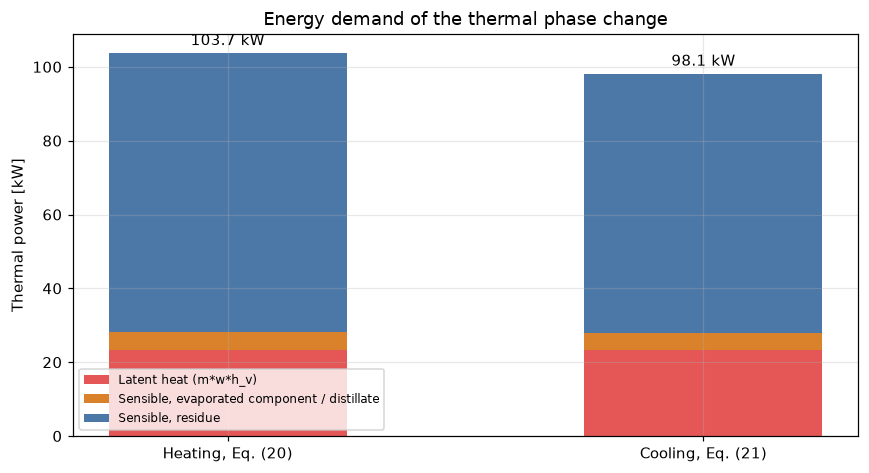

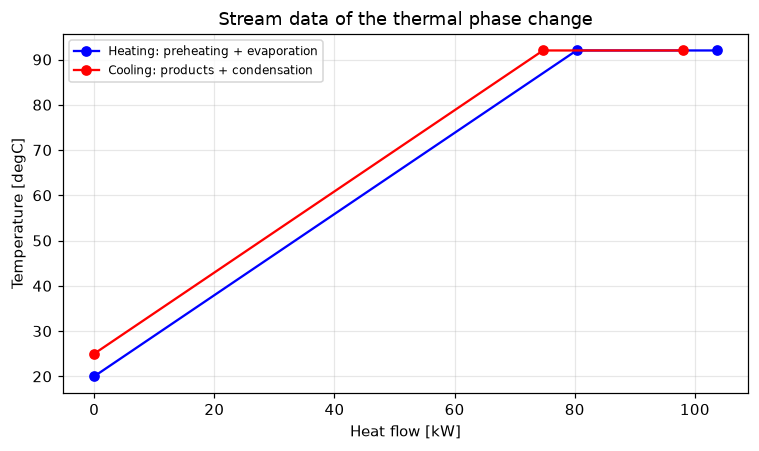

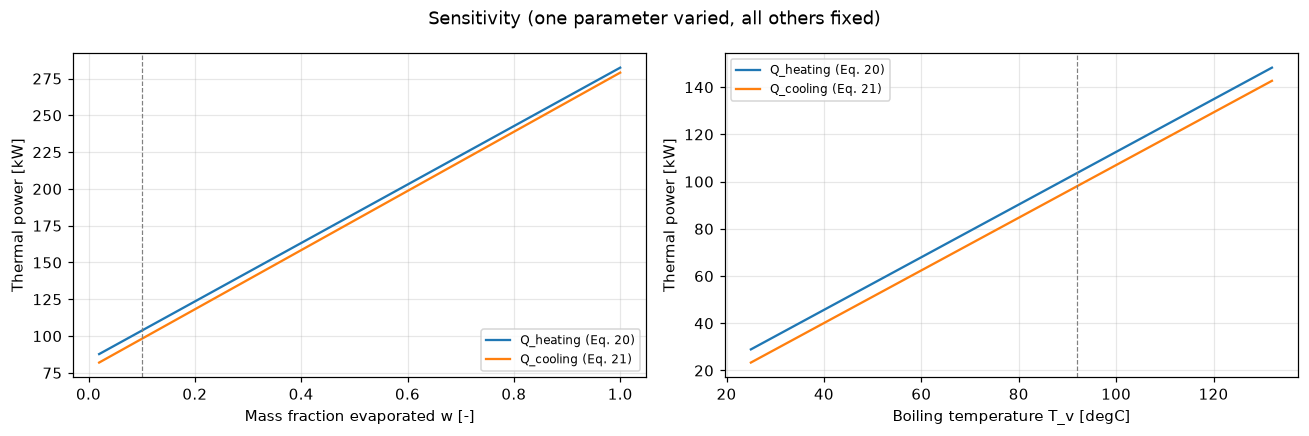

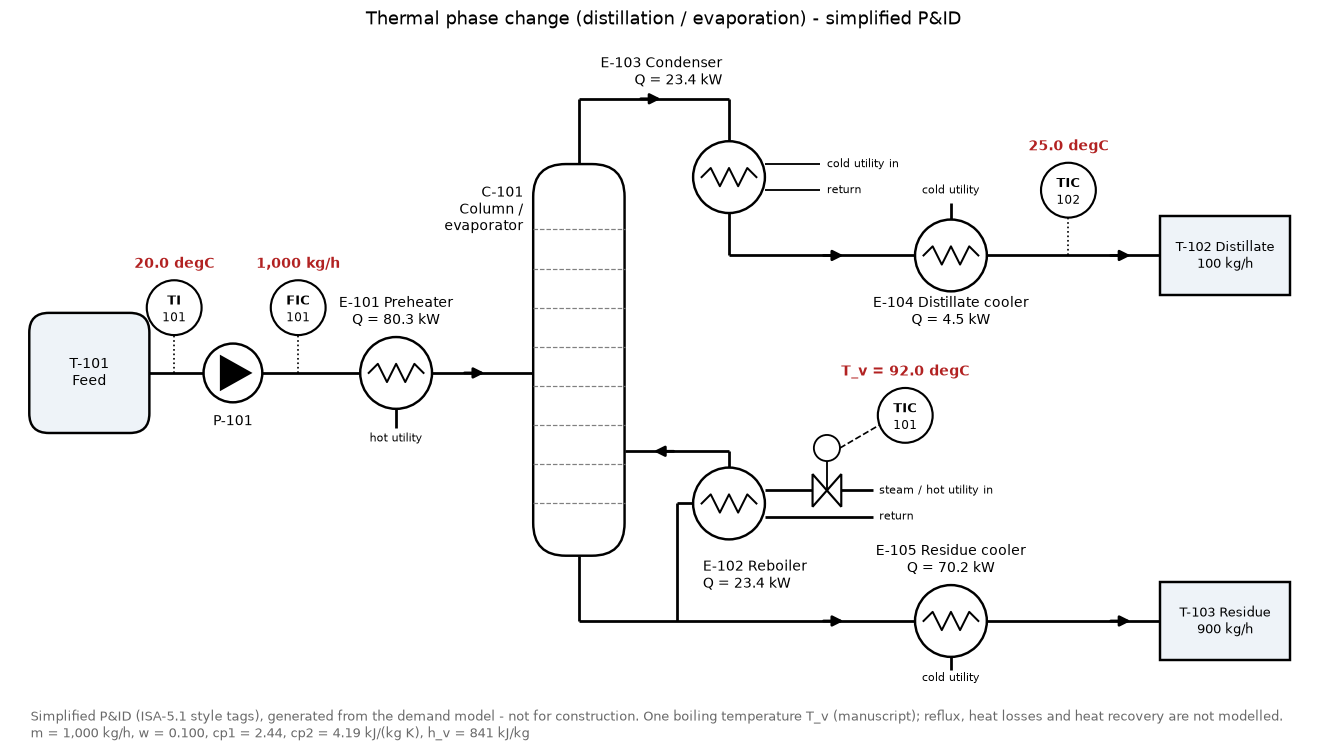

In [6]:
for fn in (plot_demand_breakdown, plot_stream_data, plot_sensitivity):
    fn(result)
    plt.show()

fig = draw_pid(result)
fig.savefig("pid.svg", bbox_inches="tight")   # P&ID of example 1a, kept next to model.py
plt.show()

## 3  Validation against the manuscript
The manuscript validates the model with a distillation case against simulation data of a literature
distillation column (reference [27]):

| | Value (p. 19) | Value (p. 23) |
|---|---|---|
| Modelled energy demand | 1,395.77 kW | 1,395.77 kJ/kg |
| Reference energy demand | 1,787.40 kW | 1,787.4 kJ/kg |
| RMSE | 391.63 kW | – |
| Relative deviation | 28.06 % | – |

**Points found in the manuscript (please check):**
1. **No inputs are given for the validation case** (feed flow, $w$, $T_{in}$, $T_v$, $T_{out}$, $c_{p,1}$, $c_{p,2}$, $h_v$),
   so the 1,395.77 cannot be recalculated here. The legacy `classes.DistillationEnergyDemand` (mentioned in the
   original notebook) or its main.py example would close this gap.
2. **Unit:** p. 19 gives kW, p. 23 gives kJ/kg for the same numbers. For kJ/kg the basis (per kg feed or per kg
   distillate) is not stated. The results table gives both specific values.
3. The 28.06 % refers to the model value (391.63 / 1,395.77); relative to the reference it is 21.91 %.
4. The manuscript explains the deviation with the missing heat losses. Fig. 8 shows a UA-value of the column, but
   Eq. (20)/(21) have no loss term, so the model has none either.
5. One boiling temperature $T_v$ for evaporation and condensation; a real column is colder at the top than at the
   bottom. Reflux is not part of the model.
6. The utility inlet and outlet temperatures are listed as inputs but do not enter Eq. (20)/(21); they are only
   checked (inlet above $T_v$) and shown in the P&ID.

In [7]:
REF = dict(Q_model=1395.77, Q_ref=1787.40, RMSE=391.63, rel=0.2806)   # printed in the manuscript (p. 19)
dev = abs(REF["Q_model"] - REF["Q_ref"])
print(f"|model - reference| = {dev:.2f}  (manuscript RMSE: {REF['RMSE']}; one data point, so RMSE = |difference|)")
print(f"  relative to model value    : {dev / REF['Q_model']:.2%}  (manuscript: 28.06 %)")
print(f"  relative to reference value: {dev / REF['Q_ref']:.2%}")
assert abs(dev - REF["RMSE"]) < 0.01 and abs(dev / REF["Q_model"] - REF["rel"]) < 1e-4

# ---- consistency checks of the implementation -------------------------------------------------
base = dict(mass_flow_kg_h=3600, T_in=20, T_v=90, T_out=30, cp_residue=4.0, w=0.25, cp_evaporated=2.0, h_v=800)
r, _ = run_process(KEY, **base)                                                        # m = 1 kg/s
assert abs(r.Q_heating - (0.25 * (800 + 2.0 * 70) + 0.75 * 4.0 * 70)) < 1e-9         # Eq. (20) by hand
assert abs(r.Q_cooling - (0.25 * (800 + 2.0 * 60) + 0.75 * 4.0 * 60)) < 1e-9         # Eq. (21) by hand
assert abs(r.Q_heating - r.Q_cooling - r.CP_liquid * (base["T_out"] - base["T_in"])) < 1e-9   # energy balance
st = r.stream_table()
assert abs(sum(s["Q_kW"] for s in st if s["type"] == "cold") - r.Q_heating) < 1e-9     # streams carry Eq. (20)
assert abs(sum(s["Q_kW"] for s in st if s["type"] == "hot") - r.Q_cooling) < 1e-9      # streams carry Eq. (21)
r_flow, _ = run_process(KEY, **{k: x for k, x in base.items() if k != "w"}, evaporated_flow_kg_h=900)
assert abs(r_flow.Q_heating - r.Q_heating) < 1e-9                                      # w or evaporated flow
print("All consistency checks passed.")

|model - reference| = 391.63  (manuscript RMSE: 391.63; one data point, so RMSE = |difference|)
  relative to model value    : 28.06%  (manuscript: 28.06 %)
  relative to reference value: 21.91%
All consistency checks passed.


## 4  Comparison with an existing implementation
Not possible yet: the original notebook `energy_demand_models_notebook_1.ipynb` only lists this process as *planned*,
and the legacy `classes.DistillationEnergyDemand` it mentions is not in the repository. With that code (or its
example inputs) this section can compare both, as for continuous heating of fluid.